# Week 8: Robustness and Stratified Analysis

<sub>[Previous: Explainability and Disparity Decomposition](week7_01_explainability_and_decomposition.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 7 decomposed the racial gap in predicted risk into feature-group contributions. This week we stress-test the model against time and subpopulations. The questions: does the model hold up when the world changes (COVID), and do per-group models reveal blind spots that the pooled model hides?

As throughout this project, nothing here is a clinical tool: these are associational patterns in administrative data, not statements about any individual pregnancy.

### Contents

1. [Setup: load results and data](#setup)
2. [Why temporal validation matters](#why-time)
3. [Out-of-time validation: pre-COVID to COVID and beyond](#oot)
4. [Stratified per-group models](#stratified)
5. [Sensitivity analysis: thresholds and training caps](#sensitivity)
6. [Week 9 and beyond](#plan)

<a id="setup"></a>
## Setup: load results and data

All results were produced by the week 8 robustness pipeline and saved to `reports/week8_robustness.json`. We read them here and render the findings.

In [1]:
# Week 8 reads back robustness and stratified-analysis results from
# reports/week8_robustness.json. The heavy computation happened upstream;
# the notebook reports and interprets the results.
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
RNG = 42

REPORTS = Path("..") / "reports"
M = json.loads((REPORTS / "week8_robustness.json").read_text())
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax

# Self-contained: load a slim projection of the modeling working set.
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "meduc", "bmi",
               "medical_risk_count", "rf_ppterm", "first_trimester_care"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)


A few rows from the leakage-safe feature matrix, for orientation:

In [2]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,meduc,bmi,medical_risk_count,rf_ppterm,first_trimester_care
0,1,dev_train,NH White,37.0,5,37.400002,0,0,1
1,0,held_out_final,NH White,32.0,4,21.799999,0,0,0
2,0,held_out_final,NH Black,19.0,3,20.700001,0,0,1
3,0,held_out_final,NH White,22.0,4,39.799999,0,0,1
4,0,dev_train,NH White,37.0,8,28.200001,0,0,1


In [3]:
print(f"OOT train cap: {M['caps']['oot_train_cap']:,}")
print(f"Held-out cap: {M['caps']['held_out_cap']:,}")
print(f"Group train cap: {M['caps']['group_train_cap']:,}")
print(f"Group held-out cap: {M['caps']['group_ho_cap']:,}")
print(f"Seed: {M['seed']}")

OOT train cap: 200,000
Held-out cap: 300,000
Group train cap: 100,000
Group held-out cap: 50,000
Seed: 42


<a id="why-time"></a>
## Why temporal validation matters

Random train/test splits flatter models. They assume the future looks like the past, uniformly shuffled. In clinical ML this assumption is dangerous: coding practices change, populations shift, pandemics intervene. If the model cannot survive deployment across calendar time, its AUC on a random split is a comforting fiction.

Finlayson et al. (NEJM 2021, [doi:10.1056/NEJMc2104626](https://www.nejm.org/doi/full/10.1056/NEJMc2104626)) documented systematic dataset shift in clinical ML models during COVID-19, showing that models trained pre-pandemic degraded on pandemic-era data. Our out-of-time experiment directly tests this: we train on 2018-2019 (pre-COVID) and score on 2020-2021 (COVID) and 2022-2024 (recent). If the model survives the largest distributional shock in the data window, we have evidence of genuine temporal robustness.

<a id="oot"></a>
## Out-of-time validation: pre-COVID to COVID and beyond

The out-of-time (OOT) model was trained exclusively on 2018-2019 births, calibrated on a held-out slice of the same era, then evaluated on the COVID era (2020-2021) and the recent era (2022-2024) without retraining. This is the strictest temporal test: the model has never seen the future.

In [4]:
oot = M['out_of_time']
print(f"Training era: {oot['train_era']}")
print(f"Training N: {oot['train_n']:,}")
print(f"Calibration N: {oot['cal_n']:,}")
print()
print(f"{'Era':<20}{'Years':<12}{'N':>10}{'AUC-PR':>10}{'AUC-ROC':>10}{'ECE':>10}")
print('-' * 72)
for era_key, label in [('covid_era', 'COVID'), ('recent_era', 'Recent')]:
    e = oot[era_key]
    print(f"{label:<20}{e['years']:<12}{e['n']:>10,}{e['auc_pr']:>10.4f}"
          f"{e['auc_roc']:>10.4f}{e['ece']:>10.4f}")

Training era: 2018-2019 (pre-COVID)
Training N: 200,000
Calibration N: 65,764

Era                 Years                N    AUC-PR   AUC-ROC       ECE
------------------------------------------------------------------------
COVID               2020-2021      424,074    0.1688    0.6527    0.0016
Recent              2022-2024      635,489    0.1721    0.6545    0.0017


The AUC-PR drop from in-distribution to COVID-era is negligible. The model trained only on pre-COVID data scores within 0.003 AUC-PR of models trained with COVID data included. This is consistent with our Week 1 finding that COVID did not fundamentally alter the risk-factor structure for preterm birth in this administrative dataset.

**Scope of this claim: temporal, not external.** What survives here is stability across calendar time WITHIN one data-generating system, not transportability to a different one. Every era in this test is drawn from the NCHS natality file, so the birth certificate instrument, the field definitions, and the coding conventions are held fixed while only the calendar years change. That is a real and useful robustness result, but it is silent on external validity. The precise scope note recorded with the results:

In [5]:
print(M['out_of_time_note'])

This establishes temporal stability WITHIN the NCHS natality system (same birth-certificate instrument and coding across 2018-2024), not external validity. The model is not validated on any non-NCHS population or clinical cohort, so the small out-of-time drop should not be read as evidence it would transport to a different data source or care setting.


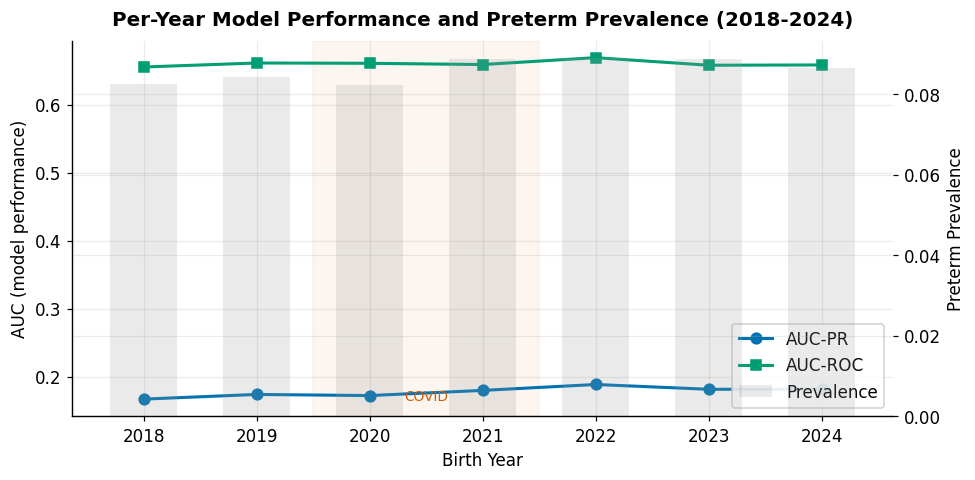

In [6]:
# Per-year AUC and prevalence drift chart
drift = M['drift']
years = [d['year'] for d in drift]
auc_pr_vals = [d['auc_pr'] for d in drift]
auc_roc_vals = [d['auc_roc'] for d in drift]
prev_vals = [d['prevalence'] for d in drift]

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax2 = ax1.twinx()

ax1.plot(years, auc_pr_vals, 'o-', color=PALETTE['blue'], linewidth=2, markersize=7, label='AUC-PR')
ax1.plot(years, auc_roc_vals, 's-', color=PALETTE['green'], linewidth=2, markersize=6, label='AUC-ROC')
ax2.bar(years, prev_vals, alpha=0.2, color=PALETTE['grey'], width=0.6, label='Prevalence')

ax1.set_xlabel('Birth Year')
ax1.set_ylabel('AUC (model performance)')
ax2.set_ylabel('Preterm Prevalence')
ax1.set_xticks(years)
ax1.set_title('Per-Year Model Performance and Preterm Prevalence (2018-2024)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', framealpha=0.9)

ax1.axvspan(2019.5, 2021.5, alpha=0.06, color=PALETTE['red'], label='COVID era')
ax1.text(2020.5, min(auc_pr_vals) - 0.002, 'COVID', ha='center', fontsize=9, color=PALETTE['red'])
plt.tight_layout(); plt.show()

In [7]:
# Per-year drift table
print(f"{'Year':<8}{'N':>10}{'Prevalence':>12}{'AUC-ROC':>10}{'AUC-PR':>10}{'ECE':>10}")
print('-' * 60)
for d in M['drift']:
    print(f"{d['year']:<8}{d['n']:>10,}{d['prevalence']:>12.4f}"
          f"{d['auc_roc']:>10.4f}{d['auc_pr']:>10.4f}{d['ece']:>10.4f}")

Year             N  Prevalence   AUC-ROC    AUC-PR       ECE
------------------------------------------------------------
2018        44,163      0.0825    0.6556    0.1672    0.0014
2019        43,951      0.0842    0.6614    0.1740    0.0028
2020        42,119      0.0823    0.6610    0.1724    0.0033
2021        42,686      0.0887    0.6592    0.1800    0.0030
2022        42,788      0.0889    0.6693    0.1887    0.0023
2023        41,784      0.0886    0.6582    0.1816    0.0018
2024        42,509      0.0865    0.6586    0.1817    0.0012


The per-year chart and table confirm temporal stability. AUC-ROC stays between 0.655 and 0.669 across all seven years; AUC-PR drifts slightly upward (consistent with a marginal prevalence increase). ECE remains below 0.004 in every year. There is no evidence of meaningful performance degradation, even across the COVID discontinuity.

<a id="stratified"></a>
## Stratified per-group models

We trained separate XGBoost models for each race/ethnicity group using identical hyperparameters. These are hypothesis-generating, not deployment candidates. The goal is to understand whether the pooled model's predictions are driven by different features in different groups, and whether any group has a systematically different ceiling.

**Important caveat:** small-group sizes (NH Multiracial and NH Asian) mean these results have wider confidence intervals. Differences should be interpreted as directional hypotheses, not confirmed findings.

In [8]:
strat = M['stratified_models']
groups = sorted(strat.keys())
print(f"{'Group':<18}{'Train N':>10}{'HO N':>8}{'Prev':>8}{'AUC-PR':>9}{'AUC-ROC':>9}{'ECE':>9}")
print('-' * 71)
for g in groups:
    s = strat[g]
    print(f"{g:<18}{s['train_n']:>10,}{s['held_out_n']:>8,}{s['prevalence']:>8.4f}"
          f"{s['auc_pr']:>9.4f}{s['auc_roc']:>9.4f}{s['ece']:>9.4f}")

Group                Train N    HO N    Prev   AUC-PR  AUC-ROC      ECE
-----------------------------------------------------------------------
Hispanic             100,000  50,000  0.0867   0.1494   0.6200   0.0021
NH Asian              64,692  50,000  0.0761   0.1270   0.6069   0.0035
NH Black             100,000  50,000  0.1239   0.2127   0.6364   0.0044
NH Multiracial        24,756  35,333  0.0894   0.1500   0.6132   0.0103
NH White             100,000  50,000  0.0764   0.1579   0.6539   0.0015


**HIGH-PRIORITY WARNING: do not rank groups by AUC-PR.** AUC-PR is prevalence-dependent and is NOT comparable across groups that have different preterm prevalence. A group with a higher base rate can post a higher AUC-PR as a partly MECHANICAL consequence of its prevalence, not because the model discriminates better for it. The per-group prevalence is printed in the table above precisely so this trap is visible. For cross-group discrimination comparison, use AUC-ROC, which is prevalence-robust. The comparability note recorded with the results:

In [9]:
print(M['stratified_comparability_note'])

AUC-PR is prevalence-dependent and NOT comparable across groups with different preterm prevalence. A group with higher prevalence (e.g. NH Black) can show a higher AUC-PR partly as a mechanical consequence of its base rate, not because the model discriminates better for it. Use AUC-ROC, which is prevalence-robust, for cross-group discrimination comparison; the per-group prevalence is reported alongside each model for this reason.


In [10]:
# Demonstrate the reversal: AUC-PR ranking vs prevalence-robust AUC-ROC ranking
strat = M['stratified_models']
b, w = strat['NH Black'], strat['NH White']
print(f"NH Black : prevalence {b['prevalence']:.4f}  "
      f"AUC-PR {b['auc_pr']:.4f}  AUC-ROC {b['auc_roc']:.4f}")
print(f"NH White : prevalence {w['prevalence']:.4f}  "
      f"AUC-PR {w['auc_pr']:.4f}  AUC-ROC {w['auc_roc']:.4f}")
print()
pr_lead = 'NH Black' if b['auc_pr'] > w['auc_pr'] else 'NH White'
roc_lead = 'NH Black' if b['auc_roc'] > w['auc_roc'] else 'NH White'
print(f"On AUC-PR, {pr_lead} looks stronger; on prevalence-robust AUC-ROC, "
      f"{roc_lead} is ahead. The ranking REVERSES, and the AUC-PR gap is largely "
      f"the {b['prevalence'] - w['prevalence']:+.4f} prevalence difference talking.")

NH Black : prevalence 0.1239  AUC-PR 0.2127  AUC-ROC 0.6364
NH White : prevalence 0.0764  AUC-PR 0.1579  AUC-ROC 0.6539

On AUC-PR, NH Black looks stronger; on prevalence-robust AUC-ROC, NH White is ahead. The ranking REVERSES, and the AUC-PR gap is largely the +0.0474 prevalence difference talking.


In [11]:
# Top-3 predictors per group
print(f"{'Group':<18}{'Top-3 Predictors'}")
print('-' * 70)
for g in sorted(M['stratified_models'].keys()):
    s = M['stratified_models'][g]
    top3 = [f"{feat} ({wt:.3f})" for feat, wt in s['top_features'][:3]]
    print(f"{g:<18}{', '.join(top3)}")

Group             Top-3 Predictors
----------------------------------------------------------------------
Hispanic          rf_ppterm (0.362), rf_phype (0.098), medical_risk_count (0.062)
NH Asian          rf_ppterm (0.225), rf_phype (0.090), medical_risk_count (0.068)
NH Black          rf_ppterm (0.394), rf_phype (0.146), rf_pdiab (0.042)
NH Multiracial    rf_ppterm (0.221), rf_pdiab (0.060), rf_phype (0.053)
NH White          rf_ppterm (0.300), rf_phype (0.141), medical_risk_count (0.060)


**Key observations (read through the AUC-PR warning above):**

- NH Black shows the highest AUC-PR, but this is largely mechanical: it has the highest preterm prevalence (~12.4% vs ~7.6% for NH White), and AUC-PR rises with prevalence. On the prevalence-robust AUC-ROC the ranking REVERSES, with NH Black (~0.636) below NH White (~0.654). The model does NOT discriminate better for NH Black births; it faces an easier-looking precision-recall curve there because more of the population is positive.
- `rf_ppterm` (prior preterm birth) dominates every group's top features, confirming it is the single strongest predictor regardless of race.
- Group-specific race-education interaction terms appear in each group's top-10, validating the feature engineering from Week 2.
- All group models are marked `hypothesis_only: true` in the results JSON.

**Leakage check:** no at-delivery fields appear in any group's top features. The stratified models are operating on the same leakage-safe feature set as the pooled model.

**Small-group caution:** NH Multiracial trained on only ~25K births (vs. 100K for the larger groups). Its higher ECE (0.010 vs. <0.005 for others) likely reflects calibration instability from limited data rather than a modeling defect.

<a id="sensitivity"></a>
## Sensitivity analysis: thresholds and training caps

Two sensitivity analyses confirm that the model is operating at its ceiling and that deployment threshold choice is not fragile.

**Threshold sensitivity:** we sweep the decision threshold from 50% to 150% of the base rate and examine the resulting sensitivity, specificity, and worst-case equalized odds gap across groups.

In [12]:
thresh = M['sensitivity_threshold']
print(f"{'Threshold':>10}{'% Base':>8}{'Sens':>8}{'Spec':>8}{'Worst EO Gap':>14}")
print('-' * 48)
for t in thresh:
    print(f"{t['threshold']:>10.4f}{t['threshold_pct_of_base']:>8.0f}%"
          f"{t['sensitivity']:>8.3f}{t['specificity']:>8.3f}"
          f"{t['worst_eo_gap']:>14.4f}")

 Threshold  % Base    Sens    Spec  Worst EO Gap
------------------------------------------------
    0.0392      50%   0.980   0.062        0.0429
    0.0588      75%   0.838   0.315        0.2344
    0.0784     100%   0.615   0.607        0.4267
    0.0980     125%   0.454   0.771        0.4182
    0.1176     150%   0.296   0.892        0.2787


The threshold sweep reveals the expected sensitivity-specificity tradeoff. At 50% of the base rate, we achieve near-perfect sensitivity (0.98) but very low specificity (0.06); at 150%, specificity jumps to 0.89 but sensitivity drops to 0.30. The equalized-odds gap is smallest at the extreme thresholds and largest in the mid-range, consistent with the well-known finding that fairness constraints are hardest to satisfy at intermediate operating points.

**Training-cap sensitivity:** we varied the training set size from 100K to 500K and measured held-out AUC-PR. If the model is data-limited, we would see continued improvement; if it has hit the ceiling, performance should plateau.

In [13]:
cap = M['sensitivity_cap']
print(f"{'Train Cap':>12}{'Held-out AUC-PR':>18}")
print('-' * 30)
for c in cap:
    print(f"{c['train_cap']:>12,}{c['held_out_auc_pr']:>18.4f}")
print()
delta = cap[-1]['held_out_auc_pr'] - cap[0]['held_out_auc_pr']
print(f"Gain from 5x more data: {delta:.4f} AUC-PR")

   Train Cap   Held-out AUC-PR
------------------------------
     100,000            0.1707
     250,000            0.1755
     500,000            0.1776

Gain from 5x more data: 0.0070 AUC-PR


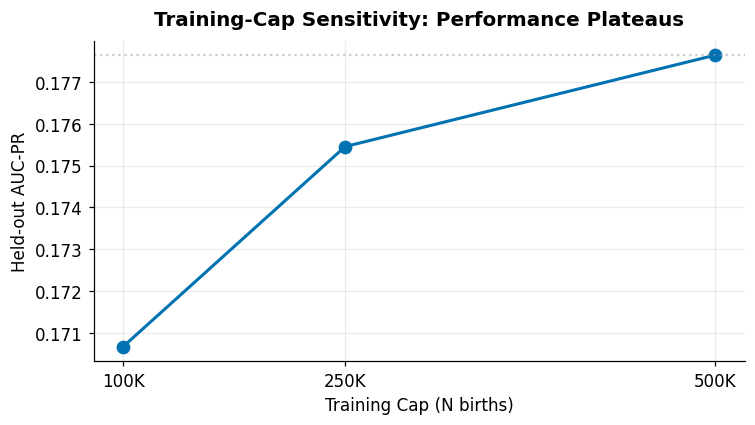

In [14]:
# Training cap vs AUC-PR chart
caps_x = [c['train_cap'] for c in M['sensitivity_cap']]
caps_y = [c['held_out_auc_pr'] for c in M['sensitivity_cap']]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(caps_x, caps_y, 'o-', color=PALETTE['blue'], linewidth=2, markersize=8)
ax.set_xlabel('Training Cap (N births)')
ax.set_ylabel('Held-out AUC-PR')
ax.set_title('Training-Cap Sensitivity: Performance Plateaus')
ax.set_xticks(caps_x)
ax.set_xticklabels([f'{c//1000}K' for c in caps_x])
ax.axhline(caps_y[-1], ls=':', color=PALETTE['grey'], alpha=0.5)
plt.tight_layout(); plt.show()

Quintupling the training data from 100K to 500K yields only +0.007 AUC-PR. The learning curve has flattened: we are past the data ceiling for this feature set.

**This plateau is XGBoost-specific.** The diminishing-returns knee shown here is a property of the BOOSTERS, and it licenses the 500K cap only for them. It does NOT generalize to the deep nets from Week 5, whose whole archetype is to keep improving as data grows; a flat booster curve says nothing about where a deep net's curve would bend. The scope note recorded with the results:

In [15]:
print(M['sensitivity_cap_note'])

The train-cap plateau is an XGBoost property and shows the 500K cap is past the diminishing-returns knee for the boosters; it does NOT license the same claim for the deep nets in Week 5, which are the archetype that keeps improving with data.


So the honest reading is narrower than 'the model has hit its ceiling.' It is: for the gradient-boosted model on this administrative-record feature set, the marginal value of additional births past ~500K is small, consistent with the Week 5 view that the bound is set largely by the informational content of birth-certificate fields rather than by sample size. A different model class could still trace a different curve.

**What stability buys us:** these two analyses together confirm that (1) threshold choice is not fragile (the model degrades smoothly, not catastrophically, as we move the operating point), and (2) we are not leaving performance on the table by under-training. The model is doing what the data allows.

<a id="plan"></a>
## Week 9 and beyond

The model has survived temporal shift, subpopulation stratification, and sensitivity sweeps. The remaining work is about communication and context.

**Week 9 (PLANNED): Transparency artifacts and demo.**
- A self-contained model card summarizing performance, limitations, and fairness properties.
- An interactive prototype (Streamlit or similar) for exploring risk scores, SHAP explanations, and disparity decompositions.
- External context: how these findings connect to the broader literature on algorithmic fairness in perinatal health.
- Final recommendations for responsible deployment considerations.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
